# Thực hiện trực quan hóa dữ liệu trên tập dữ liệu về bệnh tiểu đường

## 1. Import thư viện và đọc dữ liệu

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Thiết lập biểu đồ
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 110

# Đọc dữ liệu
df = pd.read_csv("diabetes (1).csv")

print("Kích thước dữ liệu:", df.shape)
display(df.head())

# Kiểm tra dữ liệu
print("\nThông tin dataset:")
df.info()


Kích thước dữ liệu: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1



Thông tin dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


## 2. Trực quan hóa dữ liệu bằng Matplotlib

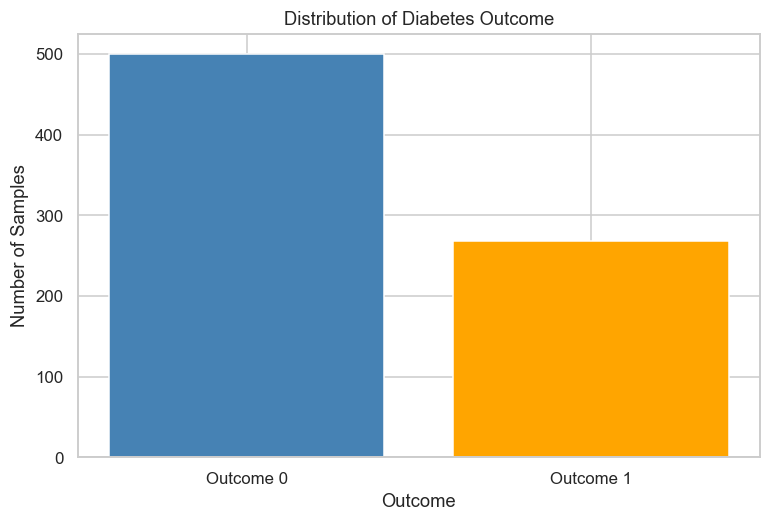

In [2]:

outcome_counts = df["Outcome"].value_counts().sort_index()

plt.figure(figsize=(8, 5))

plt.bar(
    ["Outcome 0", "Outcome 1"],
    outcome_counts.values,
    color=["steelblue", "orange"]
)

plt.title("Distribution of Diabetes Outcome")
plt.xlabel("Outcome")
plt.ylabel("Number of Samples")
plt.show()


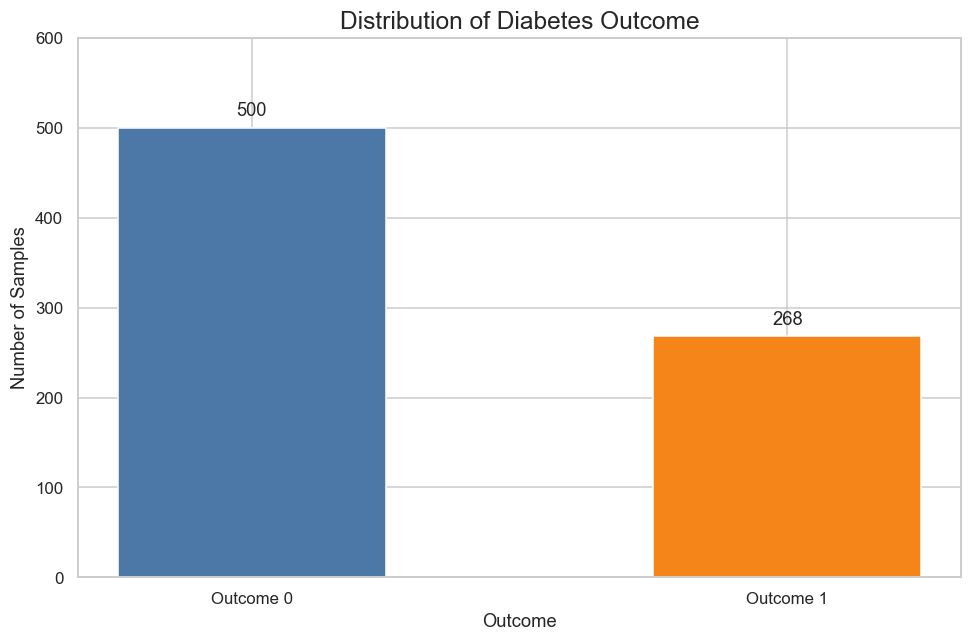

In [3]:

plt.figure(figsize=(9, 6))

bars = plt.bar(
    ["Outcome 0", "Outcome 1"],
    outcome_counts.values,
    color=["#4C78A8", "#F58518"],
    width=0.5
)

plt.bar_label(bars, padding=5, fontsize=12)

plt.title(
    "Distribution of Diabetes Outcome",
    fontsize=16
)
plt.xlabel("Outcome", fontsize=12)
plt.ylabel("Number of Samples", fontsize=12)

plt.ylim(0, 600)
plt.tight_layout()
plt.show()


## Nhận xét Bar Chart
#### Tập dữ liệu gồm 768 mẫu, trong đó:

- Outcome = 0: 500 mẫu, chiếm 65,10%.
- Outcome = 1: 268 mẫu, chiếm 34,90%.

#### Biểu đồ cho thấy số lượng mẫu Outcome = 0 lớn hơn Outcome = 1.

#### Điều này thể hiện sự chênh lệch về phân bố nhãn trong dataset.

## 3. Trực quan hóa dữ liệu bằng Seaborn

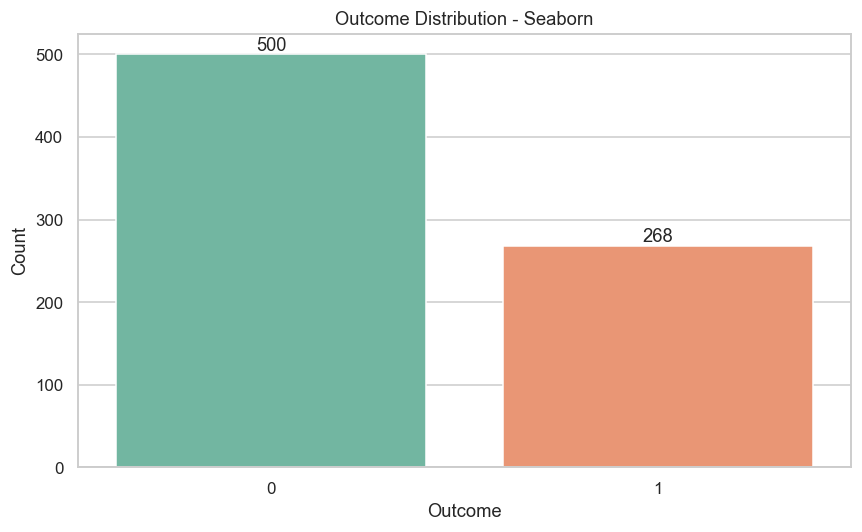

In [4]:

plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x="Outcome",
    hue="Outcome",
    palette="Set2",
    legend=False
)

for container in ax.containers:
    ax.bar_label(container)

plt.title("Outcome Distribution - Seaborn")
plt.xlabel("Outcome")
plt.ylabel("Count")
plt.tight_layout()
plt.show()


## 4. So sánh Glucose và BMI giữa hai nhóm Outcome

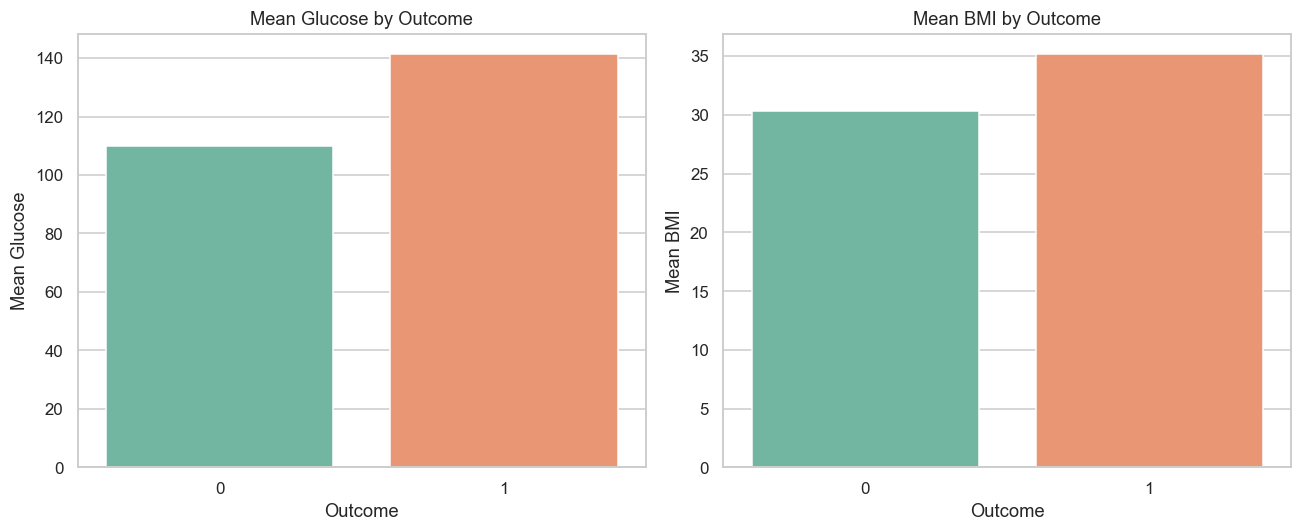

In [5]:

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 5)
)

sns.barplot(
    data=df,
    x="Outcome",
    y="Glucose",
    hue="Outcome",
    palette="Set2",
    legend=False,
    errorbar=None,
    ax=axes[0]
)

axes[0].set_title("Mean Glucose by Outcome")
axes[0].set_ylabel("Mean Glucose")

sns.barplot(
    data=df,
    x="Outcome",
    y="BMI",
    hue="Outcome",
    palette="Set2",
    legend=False,
    errorbar=None,
    ax=axes[1]
)

axes[1].set_title("Mean BMI by Outcome")
axes[1].set_ylabel("Mean BMI")

plt.tight_layout()
plt.show()


## Nhận xét kết quả Barplot
#### Giá trị Glucose trung bình:
- Outcome = 0: khoảng 109,98.
- Outcome = 1: khoảng 141,26.

#### Giá trị BMI trung bình:
- Outcome = 0: khoảng 30,30.
- Outcome = 1: khoảng 35,14.

#### Nhóm Outcome = 1 có giá trị trung bình Glucose và BMI cao hơn nhóm Outcome = 0.

#### Điều này cho thấy sự khác biệt về phân bố hai thuộc tính giữa các nhóm trong tập dữ liệu.

## 5. Biểu đồ tròn Pie Chart

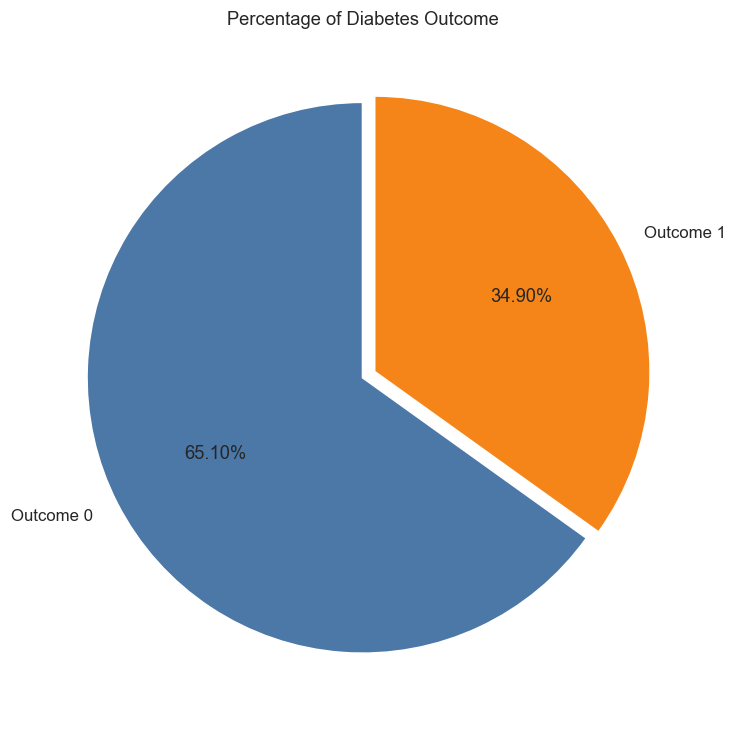

In [6]:

plt.figure(figsize=(7, 7))

plt.pie(
    outcome_counts.values,
    labels=["Outcome 0", "Outcome 1"],
    autopct="%1.2f%%",
    startangle=90,
    colors=["#4C78A8", "#F58518"],
    explode=(0, 0.05)
)

plt.title("Percentage of Diabetes Outcome")
plt.tight_layout()
plt.show()


## Nhận xét Pie Chart

#### Biểu đồ tròn thể hiện tỷ lệ phần trăm giữa hai nhóm Outcome.

#### Outcome = 0 chiếm 65,10%, trong khi Outcome = 1 chiếm 34,90%.

#### Biểu đồ giúp quan sát trực quan sự chênh lệch giữa hai nhóm trong toàn bộ dataset.

## 6. Phân tích phân bố dữ liệu bằng Histogram

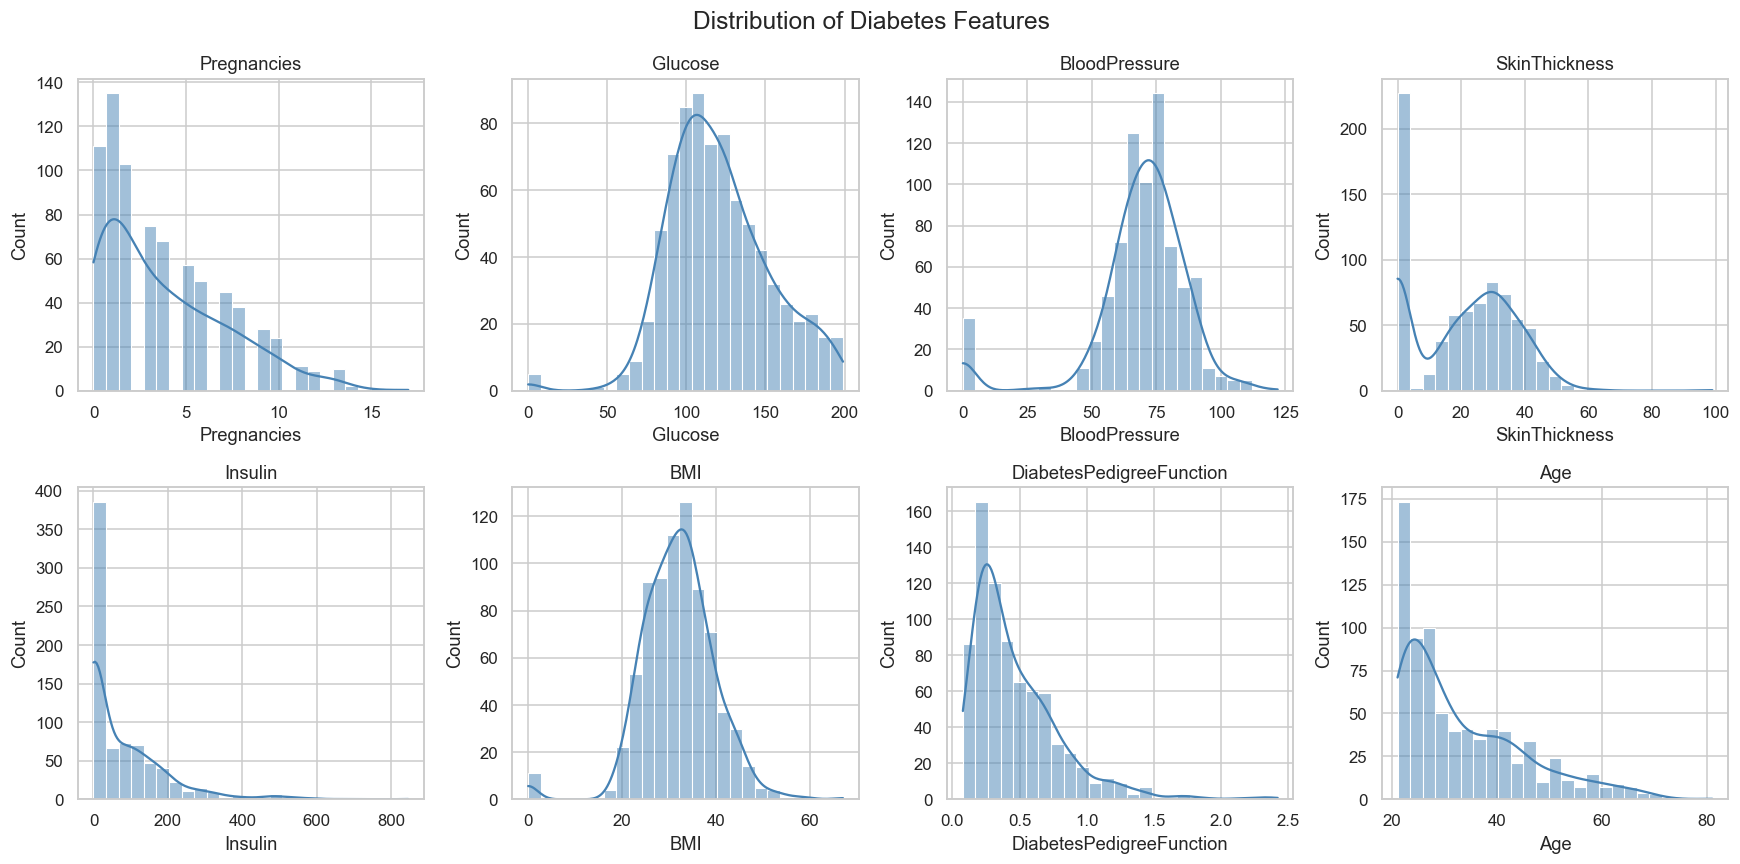

In [7]:

features = df.drop(columns="Outcome").columns

fig, axes = plt.subplots(
    2, 4,
    figsize=(16, 8)
)

for ax, col in zip(axes.flat, features):
    sns.histplot(
        data=df,
        x=col,
        kde=True,
        bins=25,
        ax=ax,
        color="steelblue"
    )

    ax.set_title(col)

plt.suptitle(
    "Distribution of Diabetes Features",
    fontsize=16
)

plt.tight_layout()
plt.show()


## Nhận xét Histogram
#### Quan sát biểu đồ cho thấy các thuộc tính có hình dạng phân bố khác nhau.

- Insulin: Phân bố lệch phải rõ rệt và có nhiều giá trị bằng 0.
- Age: Tập trung nhiều ở nhóm tuổi thấp, có xu hướng lệch phải.
- DiabetesPedigreeFunction: Phần lớn giá trị tập trung ở vùng thấp.
- Glucose: Dữ liệu tập trung nhiều ở vùng giá trị trung tâm, nhưng xuất hiện một số giá trị 0 bất thường.
- SkinThickness: Có nhiều giá trị 0 ảnh hưởng đến hình dạng phân bố.

#### Nhìn chung, dữ liệu không có cùng một dạng phân bố và cần được xem xét riêng theo từng thuộc tính.

## 7. Boxplot và Violin Plot

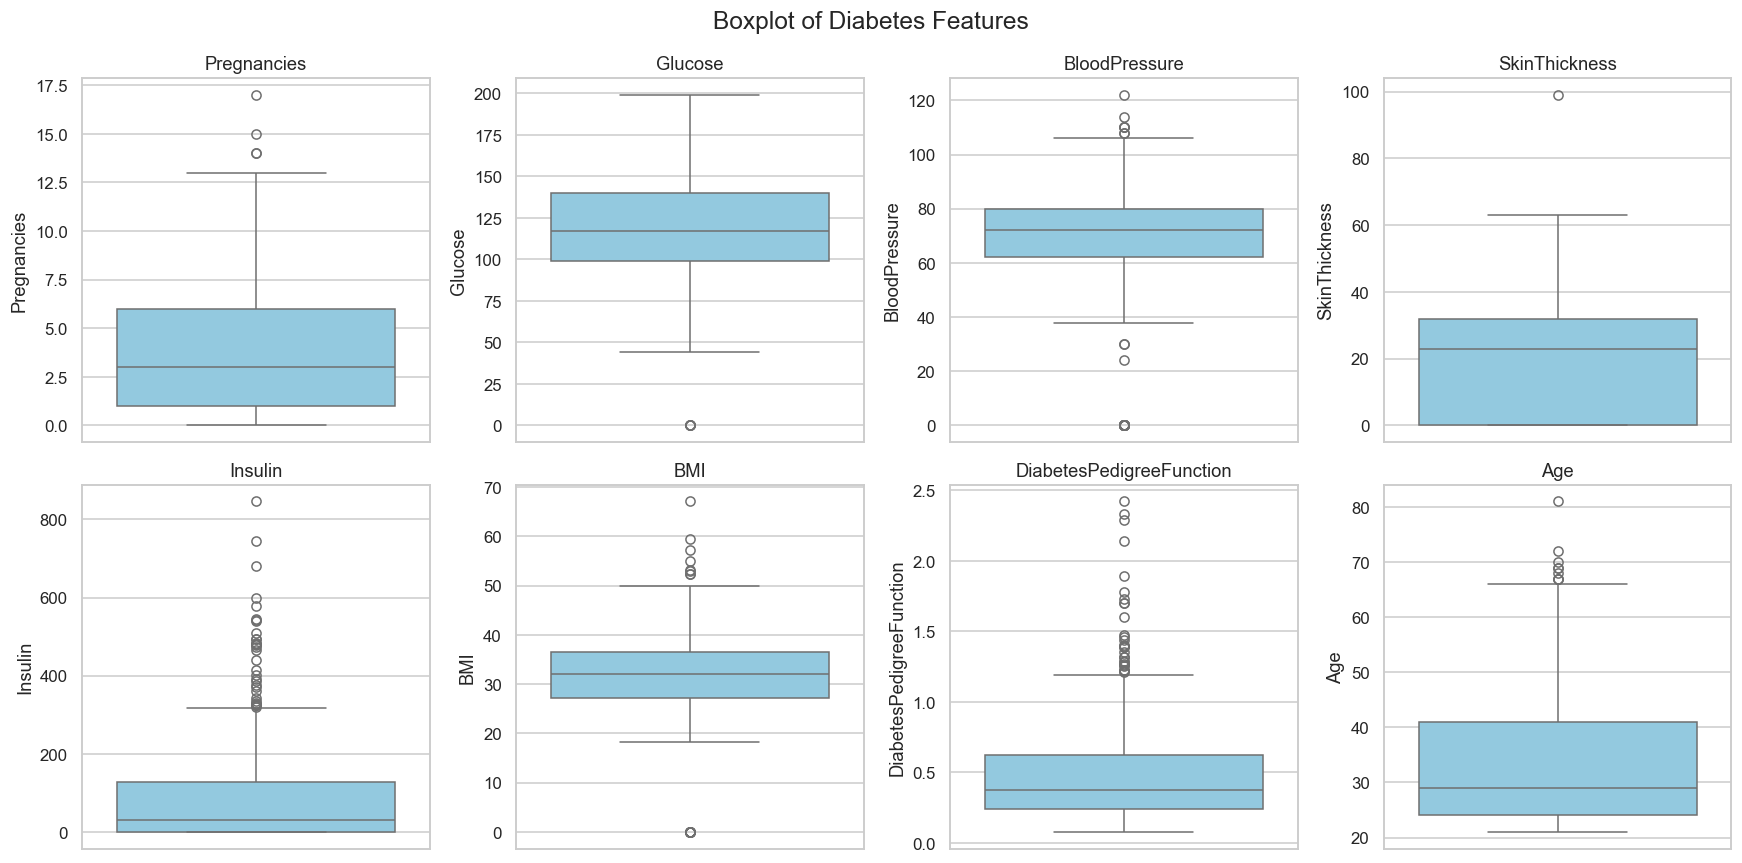

In [8]:

fig, axes = plt.subplots(
    2, 4,
    figsize=(16, 8)
)

for ax, col in zip(axes.flat, features):
    sns.boxplot(
        data=df,
        y=col,
        ax=ax,
        color="skyblue"
    )

    ax.set_title(col)

plt.suptitle(
    "Boxplot of Diabetes Features",
    fontsize=16
)

plt.tight_layout()
plt.show()


## 8. Boxplot Glucose và BMI theo Outcome

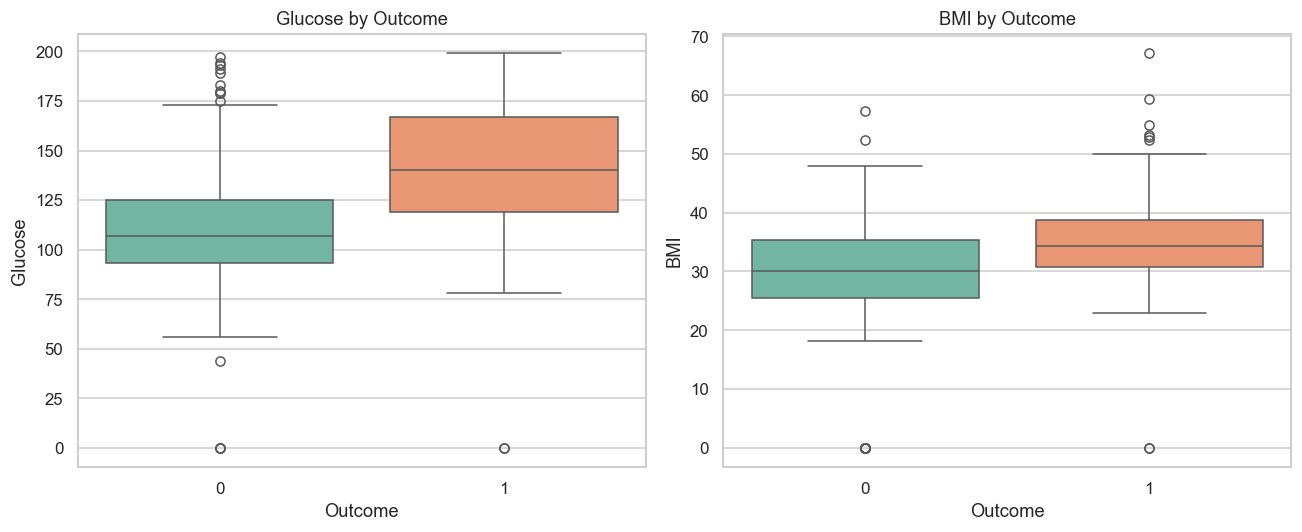

In [9]:

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 5)
)

sns.boxplot(
    data=df,
    x="Outcome",
    y="Glucose",
    hue="Outcome",
    palette="Set2",
    legend=False,
    ax=axes[0]
)

axes[0].set_title("Glucose by Outcome")

sns.boxplot(
    data=df,
    x="Outcome",
    y="BMI",
    hue="Outcome",
    palette="Set2",
    legend=False,
    ax=axes[1]
)

axes[1].set_title("BMI by Outcome")

plt.tight_layout()
plt.show()


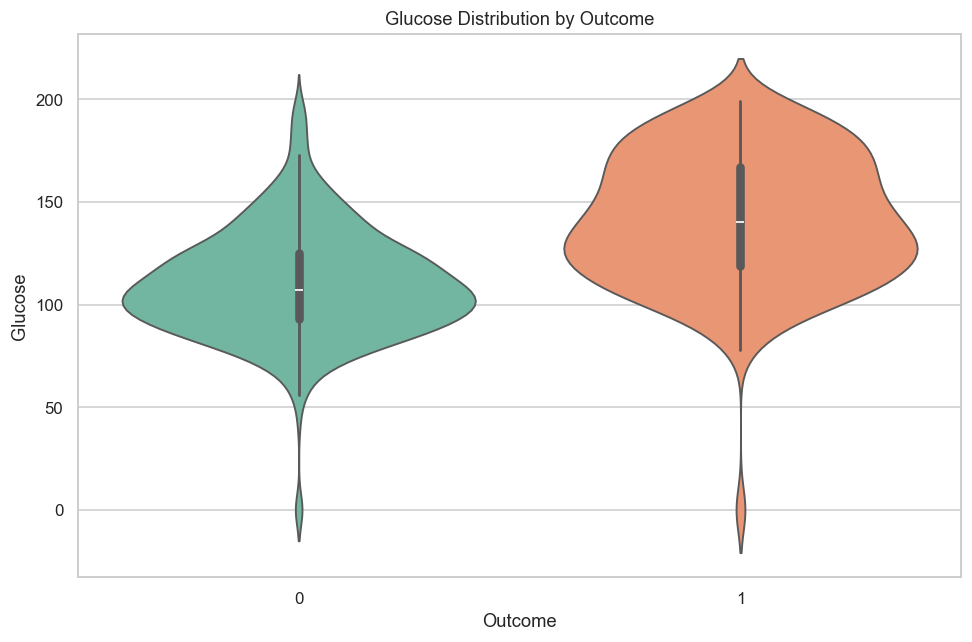

In [10]:

plt.figure(figsize=(9, 6))

sns.violinplot(
    data=df,
    x="Outcome",
    y="Glucose",
    hue="Outcome",
    palette="Set2",
    legend=False
)

plt.title("Glucose Distribution by Outcome")
plt.xlabel("Outcome")
plt.ylabel("Glucose")
plt.tight_layout()
plt.show()


## Nhận xét
#### Boxplot cho thấy một số thuộc tính xuất hiện các quan sát nằm ngoài râu hộp, đặc biệt là Insulin và DiabetesPedigreeFunction.

#### Violin Plot thể hiện hình dạng phân bố Glucose của hai nhóm Outcome.

#### Nhóm Outcome = 1 có xu hướng tập trung ở các giá trị Glucose cao hơn nhóm Outcome = 0.

#### Các biểu đồ giúp quan sát sự khác biệt về phân bố, trung vị và độ phân tán của dữ liệu.

#### Lưu ý rằng các giá trị ngoại lai không nhất thiết là dữ liệu sai và không nên tự động loại bỏ.

## 9. Scatter Plot và Heatmap

### 9.1 Scatter Plot

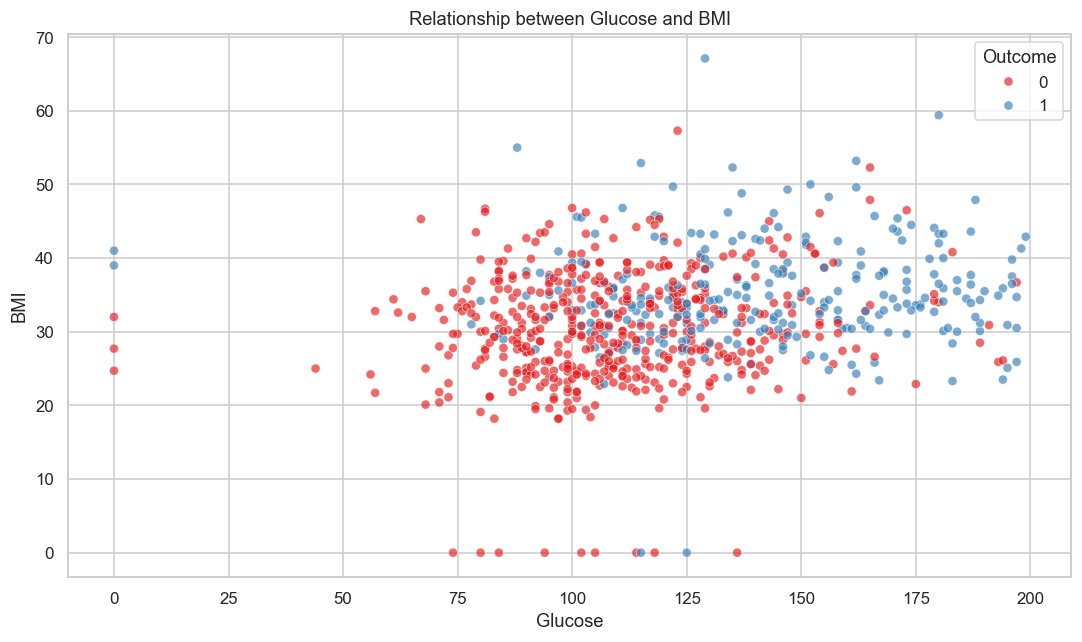

In [11]:

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Glucose",
    y="BMI",
    hue="Outcome",
    palette="Set1",
    alpha=0.65
)

plt.title("Relationship between Glucose and BMI")
plt.xlabel("Glucose")
plt.ylabel("BMI")
plt.tight_layout()
plt.show()


### 9.2 Correlation Heatmap

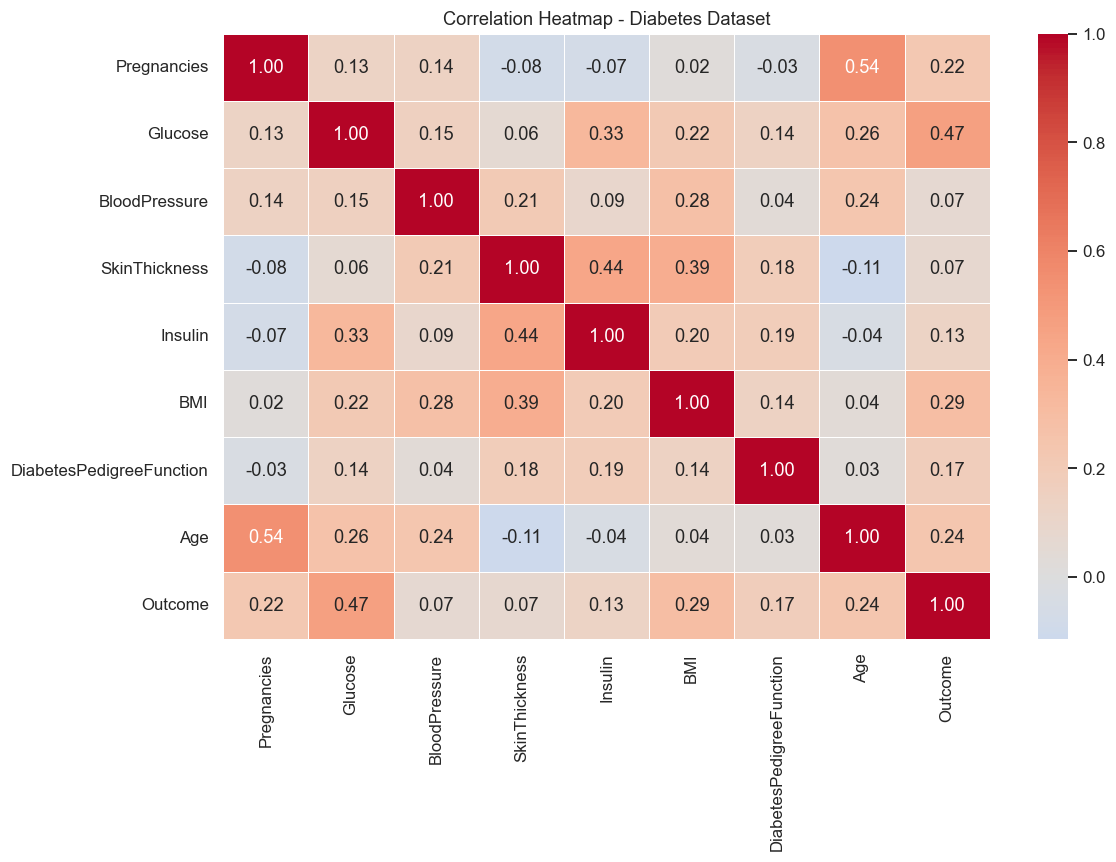

In [12]:

corr = df.corr(numeric_only=True)

plt.figure(figsize=(11, 8))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Correlation Heatmap - Diabetes Dataset")
plt.tight_layout()
plt.show()


## Nhận xét Scatter Plot và Correlation Heatmap
#### Scatter Plot cho thấy hai nhóm Outcome có sự chồng lấp trong không gian Glucose và BMI, do đó không thể phân biệt hoàn toàn hai nhóm chỉ bằng hai thuộc tính này.

#### Correlation Heatmap cho thấy:

- Glucose và Outcome có hệ số tương quan khoảng 0,47.
- BMI và Outcome có hệ số tương quan khoảng 0,29.
- Age và Outcome có hệ số tương quan khoảng 0,24.

#### Trong các thuộc tính đầu vào, Glucose có mức tương quan tuyến tính với Outcome lớn nhất.

#### Tuy nhiên, tương quan không đồng nghĩa với quan hệ nhân quả.

## 10. Kết luận
#### Qua quá trình trực quan hóa tập dữ liệu Pima Indians Diabetes, bài thực hành đã sử dụng Matplotlib và Seaborn để xây dựng các biểu đồ:

- Bar Chart và Countplot.
- Pie Chart.
- Histogram.
- Boxplot.
- Violin Plot.
- Scatter Plot.
- Correlation Heatmap.

#### Kết quả
**1. Phân bố dữ liệu**

Outcome = 0 chiếm 65,10%, cao hơn Outcome = 1 với 34,90%.

**2. Đặc điểm các thuộc tính**

Các thuộc tính có phân bố khác nhau. Một số thuộc tính như Insulin và DiabetesPedigreeFunction có phân bố lệch phải.

**3. Giá trị ngoại lai**

Boxplot cho thấy một số thuộc tính xuất hiện nhiều giá trị ngoại lai.

**4. Mối quan hệ giữa các thuộc tính**

Glucose có tương quan tuyến tính với Outcome lớn hơn các thuộc tính đầu vào còn lại.

#### Tổng kết
Bài thực hành giúp hiểu rõ cách sử dụng Matplotlib và Seaborn để phân tích và trực quan hóa dữ liệu.

Các biểu đồ hỗ trợ nhận diện đặc điểm phân bố, sự khác biệt giữa các nhóm và những giá trị bất thường trong dataset.

Kết quả là cơ sở cho các bước tiền xử lý và phân tích dữ liệu tiếp theo.